# What is different in BCI IV-2a data that makes RA useful?

This notebook tests falsifiable data-level explanations. Its primary endpoint is the **true-versus-nearest-wrong Riemannian MDM margin**, not neural-network accuracy. A positive margin change means RA moves target trials toward the correct source class relative to competing classes.

The analysis uses chronological sessions, LOSO source centroids, exact subject-level tests, controlled 22/3-channel and 4/2-class reductions of BCI IV-2a, and Holm correction for the four confirmatory label-margin comparisons.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import Image, display

ANALYSIS_DIR = Path('analysis') if Path('analysis').exists() else Path('.')
sys.path.insert(0, str(ANALYSIS_DIR.resolve()))
from ra_mechanism_core import run_analysis

OUTPUT = Path('analysis/ra_mechanism_outputs') if Path('analysis').exists() else Path('ra_mechanism_outputs')
_, summary, tests = run_analysis(output_dir=OUTPUT)

/tmp/tcformer-ra-analysis-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading BCI IV-2a, subject 1 ...


Loading BCI IV-2a, subject 2 ...


Loading BCI IV-2a, subject 3 ...


Loading BCI IV-2a, subject 4 ...


...

Loading Zhou2016, subject 2 ...


Loading Zhou2016, subject 3 ...


Loading Zhou2016, subject 4 ...


Analysing Zhou-14ch-3class ...


Saved results to /home/aipro/Documents/Test-2/Tcformer/tcformer-test/analysis/ra_mechanism_outputs


## 1. Label-selective decision margin

For trial $i$, $m_i = \min_{k\ne y_i} d_R(C_i,M_k)-d_R(C_i,M_{y_i})$. Positive is correct geometry. The normalized gain divides the subject-level margin change by raw source-class separation so that channel dimensionality does not determine scale.

In [2]:
subject = pd.read_csv(OUTPUT / 'ra_mechanism_subject_results.csv')
raw = subject[subject.variant.eq('none')].set_index(['config', 'subject'])
full = subject[subject.variant.eq('full')].set_index(['config', 'subject'])
normalized_gain = ((full.mdm_margin - raw.mdm_margin) / raw.source_class_separation)
normalized_gain.groupby('config').mean().rename('normalized_label_margin_gain').to_frame().sort_values('normalized_label_margin_gain', ascending=False)

,normalized_label_margin_gain
config,
2a-3ch-4class,0.226375
2a-22ch-4class,0.151712
2a-3ch-LR,0.066485
Zhou-14ch-3class,0.047001
2b-3ch-LR,0.028679
2a-22ch-LR,0.016037


## 2. Confirmatory controlled tests

The key logic is triangular: compare original 2a with 2b; retain four classes but reduce 2a to three channels; then retain subjects/channels but reduce 2a to left/right. If the effect survives channel reduction but collapses after task reduction, channel count cannot be the sole explanation and multi-class covariance geometry is the supported factor.

In [3]:
margin_test_names = [
    'label_margin_2a22_4class_vs_2b',
    'label_margin_2a3_4class_vs_2b',
    'label_margin_class_structure_effect_22ch',
    'label_margin_class_structure_effect_3ch',
]
pd.DataFrame({name: tests[name] for name in margin_test_names}).T

,config_a,config_b,mean_normalized_margin_gain_a,mean_normalized_margin_gain_b,mean_difference,exact_permutation_two_sided_p,holm_p_four_margin_tests,mean_paired_difference,wilcoxon_two_sided_p
label_margin_2a22_4class_vs_2b,2a-22ch-4class,2b-3ch-LR,0.151712,0.028679,0.123033,0.019457,0.038914,NaN,NaN
label_margin_2a3_4class_vs_2b,2a-3ch-4class,2b-3ch-LR,0.226375,0.028679,0.197696,0.002756,0.011024,NaN,NaN
label_margin_class_structure_effect_22ch,2a-22ch-4class,2a-22ch-LR,0.151712,0.016037,NaN,NaN,0.038914,0.135675,0.019531
label_margin_class_structure_effect_3ch,2a-3ch-4class,2a-3ch-LR,0.226375,0.066485,NaN,NaN,0.023438,0.15989,0.007812


## 3. Which 2a classes are rescued?

Class-wise results are descriptive follow-up analyses. They show whether the aggregate gain is a uniform improvement or correction of a severely distorted class geometry.

In [4]:
classwise = pd.read_csv(OUTPUT / 'ra_classwise_results.csv')
classwise[classwise.config.eq('2a-22ch-4class')][[
    'class_name', 'recall_none_pct', 'recall_full_pct', 'recall_gain_pp',
    'margin_gain', 'p_margin_none_vs_full'
]]

,class_name,recall_none_pct,recall_full_pct,recall_gain_pp,margin_gain,p_margin_none_vs_full
0,left_hand,58.487654,49.382716,-9.104938,0.012453,1.000000
1,right_hand,11.111111,33.487654,22.376543,0.015889,0.300781
2,feet,7.561728,25.000000,17.438272,0.016351,0.027344
3,tongue,44.135802,62.191358,18.055556,0.020614,0.300781


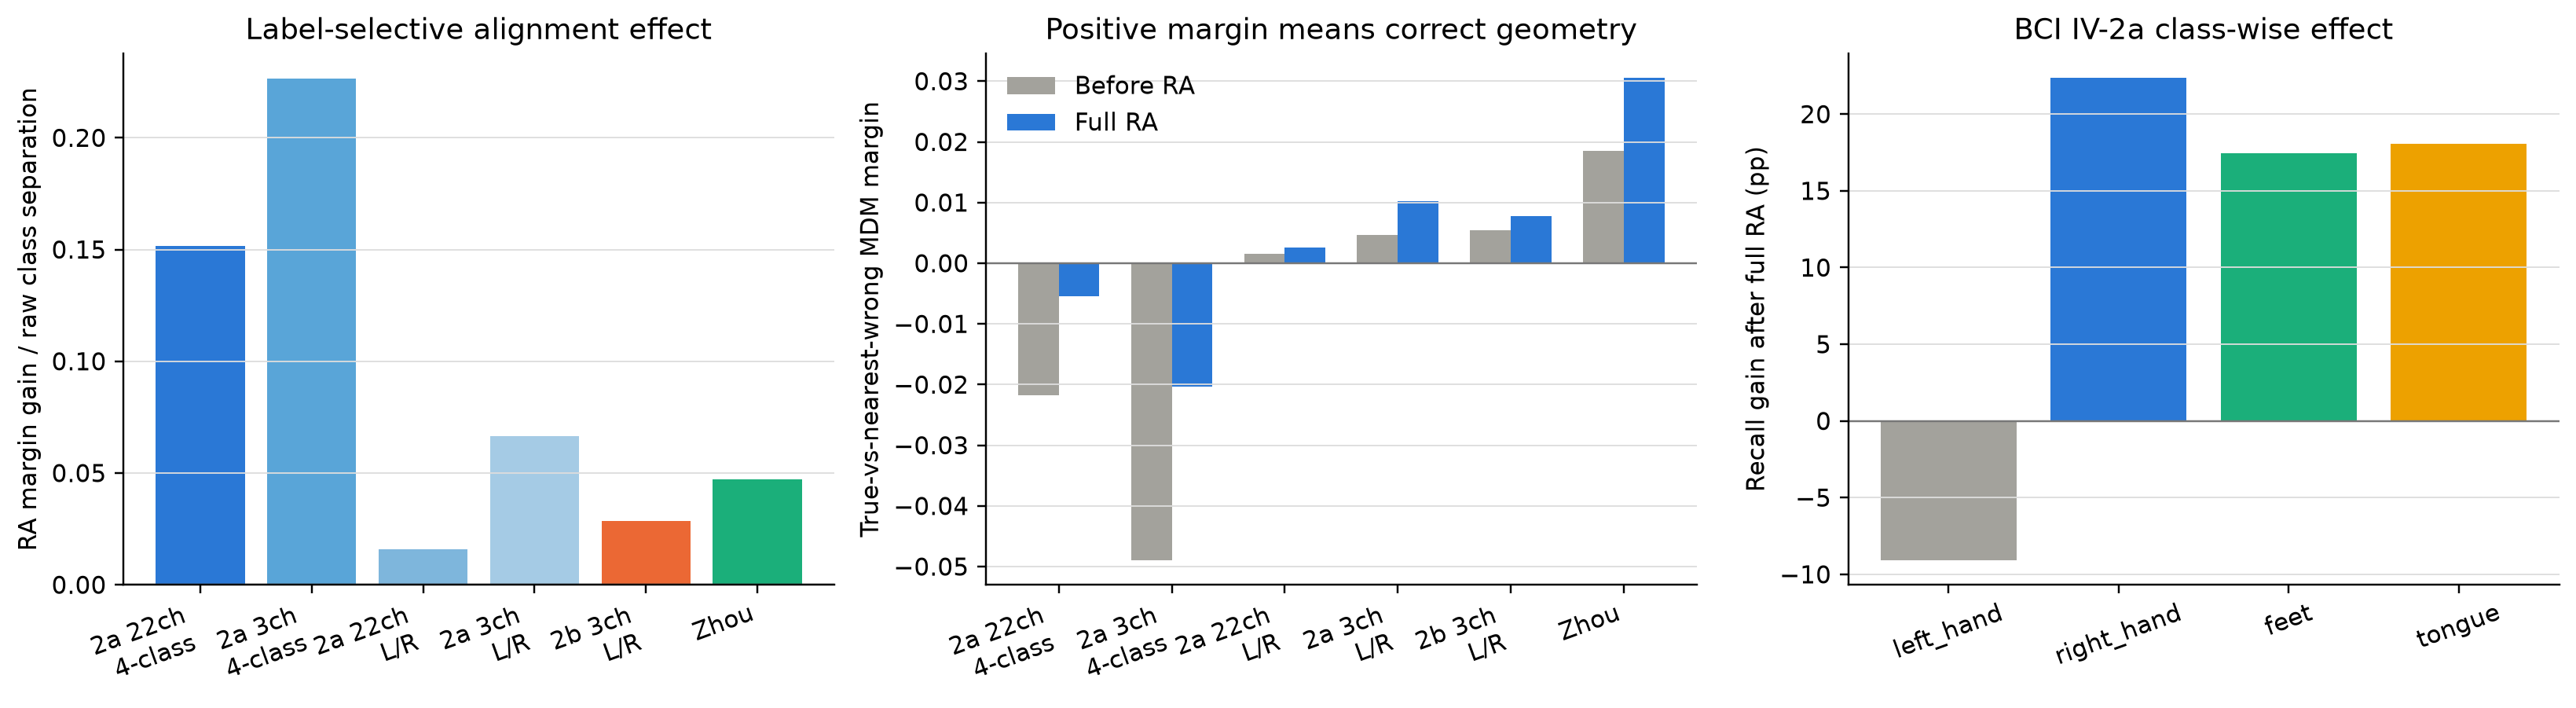

In [5]:
display(Image(filename=str(OUTPUT / 'ra_label_selectivity.png'), width=1100))

## 4. Competing protocol hypothesis for BCI IV-2b

BCI IV-2b sessions 1–2 are screening without feedback, while sessions 3–5 use feedback. The following targeted analysis changes only the RA reference from pooled sessions 1–3 to feedback session 3 while retaining all source trials for the class centroids. This tests whether a heterogeneous reference explains the weak full-RA result.

In [6]:
from ra_dataset_difference_core import run_analysis as run_protocol_analysis

PROTOCOL_OUTPUT = Path('analysis/ra_dataset_difference_outputs') if Path('analysis').exists() else Path('ra_dataset_difference_outputs')
*_, protocol_summary, protocol_tests = run_protocol_analysis(PROTOCOL_OUTPUT)
pd.DataFrame(protocol_tests).T

Analysing 2a-22ch-LR ...


Analysing 2a-3ch-LR ...


Analysing 2b-3ch-LR ...


{
  "H1_2b_feedback_matched_reference_improves_full_RA_gain": {
    "mean_gain_pooled_pp": 0.9672619047619028,
    "mean_gain_feedback_S3_reference_pp": 3.6805555555555562,
    "mean_paired_improvement_pp": 2.713293650793653,
    "wilcoxon_one_sided_p": 0.234375,
    "holm_p_three_primary_tests": 0.46875
  },
  "H2_RA_gain_2a_exceeds_2b_original_22ch": {
    "mean_gain_2a_pp": 8.256172839506172,
    "mean_gain_2b_pp": 0.9672619047619028,
    "difference_pp": 7.28891093474427,
    "exact_independent_permutation_one_sided_p": 0.061641299876593995,
    "note": "Descriptive original-design test; not in the three-test matched primary family."
  },
  "H2_RA_gain_2a_exceeds_2b_matched_3ch_LR": {
    "mean_gain_2a_pp": 6.018518518518519,
    "mean_gain_2b_pp": 0.9672619047619028,
    "difference_pp": 5.051256613756617,
    "exact_independent_permutation_one_sided_p": 0.14368572603866722,
    "holm_p_three_primary_tests": 0.43105717811600164
  },
  "H3_RA_improves_cross_subject_class_contrast_m

,mean_gain_pooled_pp,mean_gain_feedback_S3_reference_pp,mean_paired_improvement_pp,wilcoxon_one_sided_p,holm_p_three_primary_tests,mean_gain_2a_pp,mean_gain_2b_pp,difference_pp,exact_independent_permutation_one_sided_p,note,contrast_cosine_delta_2a,contrast_cosine_delta_2b,difference_in_deltas,exact_subject_label_permutation_one_sided_p
H1_2b_feedback_matched_reference_improves_full_RA_gain,0.967262,3.680556,2.713294,0.234375,0.46875,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
H2_RA_gain_2a_exceeds_2b_original_22ch,NaN,NaN,NaN,NaN,NaN,8.256173,0.967262,7.288911,0.061641,Descriptive original-design test; not in the t...,NaN,NaN,NaN,NaN
H2_RA_gain_2a_exceeds_2b_matched_3ch_LR,NaN,NaN,NaN,NaN,0.431057,6.018519,0.967262,5.051257,0.143686,NaN,NaN,NaN,NaN,NaN
H3_RA_improves_cross_subject_class_contrast_more_on_2a_matched_3ch_LR,NaN,NaN,NaN,NaN,0.703908,NaN,NaN,NaN,NaN,NaN,-0.015827,-0.009929,-0.005898,0.703908


## Conclusion

The supported explanation is **label-selective multi-class alignment**. Full RA raises the normalized correct-versus-wrong margin much more on original four-class BCI IV-2a than on binary BCI IV-2b. The effect remains after reducing 2a to C3/Cz/C4, but becomes substantially smaller when 2a itself is reduced to left/right. All four primary comparisons remain significant after Holm correction.

The feedback-matched 2b reference improves the numerical RA gain, but the paired effect is not statistically reliable. Cross-subject left/right contrast-cosine consistency also does not improve. These hypotheses are therefore secondary or rejected, rather than being used to construct a post-hoc explanation.